# E-Commerce Sales & Customer Retention Analysis

## Project overview
An online gift retailer wants to grow sales and keep customers coming back. In this project I analyze one year of its transactions to understand **what sells, when it sells, and who keeps buying**, then turn the findings into business recommendations.

## Business questions
1. **Sales:** How does revenue change over time, and when do customers buy?
2. **Products:** Which products drive the most revenue?
3. **Customers:** How many customers come back, and how much revenue do they bring?
4. **Retention:** Who is at risk of leaving, and what should the business do about it?

## Dataset
- **Source:** [UCI Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail)
- **Content:** transactions of a UK-based online retailer, 1 Dec 2010 to 9 Dec 2011
- **Currency:** British pounds (£)

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn

## 1. Setup
First I import the libraries I need. Each one has a job:
- **pandas**: tables and data cleaning
- **numpy**: math operations
- **matplotlib / seaborn**: charts

In [87]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings: readable numbers and all columns visible
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

## 2. Load the data
`InvoiceNo` and `StockCode` are identifiers, not numbers. Some contain letters (for example `C536379` marks a cancellation and `85123A` is a product code), so I load them as text to avoid losing information.

In [88]:
DATA_PATH = "../data/Online_Retail.xlsx"

df = pd.read_excel(DATA_PATH, dtype={"InvoiceNo": str, "StockCode": str})

## 3. First look at the data
Before cleaning or analyzing anything, I check the size, a sample of rows, the column types, and basic statistics. This tells me what one row means and where problems might be hiding.

In [89]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 541,909 | Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(1), str(3)
memory usage: 33.1+ MB


### Findings: first look
- The dataset has **541,909 rows** and 8 columns. Each row is one product line on an invoice, not one order.
- **`CustomerID` is missing in ~25% of rows** (135,080), which are likely guest checkouts. These rows can be used for sales analysis but not for customer or retention analysis.
- `Description` is missing in 1,454 rows (<0.3%), a minor issue.
- `CustomerID` is stored as a float because of the missing values. It should be treated as an identifier.
- Next: check `Quantity` and `UnitPrice` for invalid values.

In [91]:
print("Quantity <= 0 :", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())
print("Cancelled invoices (start with C):", df["InvoiceNo"].str.startswith("C").sum())
print("Duplicate rows:", df.duplicated().sum())


Quantity <= 0 : 10624
UnitPrice <= 0: 2517
Cancelled invoices (start with C): 9288
Duplicate rows: 5268


## 2. Data-quality audit
Before cleaning anything, I measure what is wrong with the data. 
First **quantify** each problem, then **decide** what to do about it.

In [92]:
audit = pd.DataFrame({
    "Issue": ["Missing CustomerID", "Missing Description", "Cancelled invoices (C...)",
              "Quantity <= 0", "UnitPrice <= 0", "Duplicate rows"],
    "Rows": [df["CustomerID"].isna().sum(), df["Description"].isna().sum(),
             df["InvoiceNo"].str.startswith("C").sum(), (df["Quantity"] <= 0).sum(),
             (df["UnitPrice"] <= 0).sum(), df.duplicated().sum()],
})
audit["% of rows"] = audit["Rows"] / len(df) * 100
audit



,Issue,Rows,% of rows
0,Missing CustomerID,135080,24.93
1,Missing Description,1454,0.27
2,Cancelled invoices (C...),9288,1.71
3,Quantity <= 0,10624,1.96
4,UnitPrice <= 0,2517,0.46
5,Duplicate rows,5268,0.97


### Findings: data-quality audit
| Issue | Rows | % of data |
|---|---|---|
| Missing CustomerID | 135,080 | 24.9% |
| Quantity <= 0 | 10,624 | 2.0% |
| Cancelled invoices | 9,288 | 1.7% |
| UnitPrice <= 0 | 2,517 | 0.5% |
| Duplicate rows | 5,268 | 1.0% |

- **A quarter of the rows have no CustomerID** (guest checkouts), so customer and retention analysis will use only the other 75%.
- **Cancellations are the main source of negative quantities.** They are returns, not errors, but they must not be counted as sales.
- About 1,300 negative quantities are **not** cancellations. I investigate them below.
- Every other problem is small (≤ 2% of rows), so cleaning will not change the overall picture.

In [93]:
# Negative quantity but NOT a cancellation
df[(df["Quantity"] < 0) & (~df["InvoiceNo"].str.startswith("C"))].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.00,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.00,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.00,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.00,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.00,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.00,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.00,NaN,United Kingdom


In [94]:
df[(df["Quantity"] < 0) & (~df["InvoiceNo"].str.startswith("C"))].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.00,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.00,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.00,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.00,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.00,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.00,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.00,NaN,United Kingdom


In [95]:
adjust = df[(df["Quantity"] < 0) & (~df["InvoiceNo"].str.startswith("C"))]

print("Rows:", len(adjust))
print("with UnitPrice == 0 :", (adjust["UnitPrice"] == 0).sum())
print("with no Description :", adjust["Description"].isna().sum())
print("with no CustomerID  :", adjust["CustomerID"].isna().sum())

Rows: 1336
with UnitPrice == 0 : 1336
with no Description : 862
with no CustomerID  : 1336


### Findings: negative quantities that are not cancellations
- These rows have no description, no customer and a unit price of 0. They are **stock adjustments** (damaged, lost or miscounted inventory), not sales or customer returns.
- They explain part of the overlap between the missing-description, zero-price and missing-customer issues.
- **Decision for cleaning:** remove them from the sales analysis, since they bring no revenue.

## 3. Data cleaning
Every cleaning decision is based on the audit above and recorded in a log.

| Problem | Decision | Why |
|---|---|---|
| Cancelled invoices (C...) | Move to a separate `returns` table | They are returns, not sales, but useful for a returns analysis later |
| Quantity <= 0 or UnitPrice <= 0 | Remove | Stock adjustments and errors, not real sales |
| Duplicate rows | Remove | Likely double entries |
| Missing CustomerID | **Keep** for sales analysis | Revenue is still real; only customer analysis needs an ID |

In [96]:
df_clean = df.copy()      # work on a copy, the raw data stays untouched
cleaning_log = []         # we will record every step here

def log_step(name, before, after):
    cleaning_log.append({"Step": name, "Rows removed": before - after, "Rows remaining": after})

In [97]:
before = len(df_clean)

is_cancel = df_clean["InvoiceNo"].str.startswith("C")
returns = df_clean[is_cancel].copy()      # keep them for later
df_clean = df_clean[~is_cancel]           # ~ means NOT: keep rows that are not cancellations

log_step("Move cancellations (C...) to returns table", before, len(df_clean))

In [98]:
before = len(df_clean)

df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["UnitPrice"] > 0)]

log_step("Remove Quantity <= 0 or UnitPrice <= 0", before, len(df_clean))

In [99]:
pd.DataFrame(cleaning_log)

,Step,Rows removed,Rows remaining
0,Move cancellations (C...) to returns table,9288,532621
1,Remove Quantity <= 0 or UnitPrice <= 0,2517,530104


### Findings: cleaning (part A)
- **9,288 cancellation rows** were moved to a separate `returns` table, leaving 532,621 rows.
- **2,517 rows** with a quantity or price of 0 or less were removed (stock adjustments and errors), leaving 530,104 rows. This matches the audit count exactly, which confirms that all non-cancellation negative quantities were zero-price stock adjustments.
- Duplicate rows are removed next.

### Non-product items
Some `StockCode` values are not products (postage, bank charges, manual entries). Real products have codes like `85123A` (5 digits, sometimes with a letter). I check which codes break that pattern before removing anything.

In [100]:
not_product_like = df_clean[~df_clean["StockCode"].str.match(r"^\d{5}")]

not_product_like.groupby(["StockCode", "Description"]).size().sort_values(ascending=False).head(15)

StockCode     Description                       
POST          POSTAGE                               1126
DOT           DOTCOM POSTAGE                         706
M             Manual                                 321
C2            CARRIAGE                               141
DCGSSGIRL     GIRLS PARTY BAG                         13
BANK CHARGES  Bank Charges                            12
DCGSSBOY      BOYS PARTY BAG                          11
gift_0001_20  Dotcomgiftshop Gift Voucher £20.00       9
gift_0001_10  Dotcomgiftshop Gift Voucher £10.00       8
gift_0001_30  Dotcomgiftshop Gift Voucher £30.00       7
DCGS0003      BOXED GLASS ASHTRAY                      4
gift_0001_50  Dotcomgiftshop Gift Voucher £50.00       4
gift_0001_40  Dotcomgiftshop Gift Voucher £40.00       3
PADS          PADS TO MATCH ALL CUSHIONS               3
S             SAMPLES                                  2
dtype: int64

In [101]:
NON_PRODUCT = ["POST", "DOT", "M", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "B", "C2", "PADS"]

before = len(df_clean)

df_clean = df_clean[~df_clean["StockCode"].str.upper().isin(NON_PRODUCT)]

log_step("Remove non-product StockCodes (postage, fees, manual)", before, len(df_clean))

In [102]:
print("Missing descriptions left:", df_clean["Description"].isna().sum())

df_clean["Description"] = df_clean["Description"].str.strip().str.upper()

Missing descriptions left: 0


### Findings: cleaning (part B)
- Postage, bank charges, Amazon fees and manual entries are **not products** and are removed, so they don't show up in product rankings.
- These rows carry real money, so removing them lowers total revenue slightly, but the remaining revenue is genuine product sales.
- Product descriptions were standardised (trimmed, uppercase).

### Orders that were cancelled afterwards
Cancellations were moved to the `returns` table, but the **original order is still in the sales data**. If a customer orders 80,000 units and cancels a minute later, the sale never happened, yet it would still count as revenue. I look at the biggest orders first, because that is where the damage is largest.

In [103]:
df_clean.nlargest(5, "Quantity")[["InvoiceNo", "Description", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID"]]

,InvoiceNo,Description,Quantity,UnitPrice,InvoiceDate,CustomerID
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,"16,446.00"
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,"12,346.00"
421632,573008,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,2011-10-27 12:26:00,"12,901.00"
206121,554868,SMALL POPCORN HOLDER,4300,0.72,2011-05-27 10:52:00,"13,135.00"
97432,544612,EMPIRE DESIGN ROSETTE,3906,0.82,2011-02-22 10:43:00,"18,087.00"


In [104]:
top_customers = df_clean.nlargest(2, "Quantity")["CustomerID"]

returns[returns["CustomerID"].isin(top_customers)][["InvoiceNo", "Description", "Quantity", "InvoiceDate", "CustomerID"]]

,InvoiceNo,Description,Quantity,InvoiceDate,CustomerID
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,"12,346.00"
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,"16,446.00"


In [105]:
before = len(df_clean)
revenue_before = (df_clean["Quantity"] * df_clean["UnitPrice"]).sum()

# Build a lookup of cancelled lines: same customer, same product, same quantity
cancelled = returns.dropna(subset=["CustomerID"])[["CustomerID", "StockCode", "Quantity"]].copy()
cancelled["Quantity"] = -cancelled["Quantity"]        # flip -80995 to 80995 so it can match the original
cancelled = cancelled.drop_duplicates()
cancelled["was_cancelled"] = True

# Attach the flag to the sales table, then keep only lines that were NOT cancelled
df_clean = df_clean.merge(cancelled, on=["CustomerID", "StockCode", "Quantity"], how="left")
df_clean = df_clean[df_clean["was_cancelled"].isna()].drop(columns="was_cancelled")

log_step("Remove orders later cancelled by the customer", before, len(df_clean))

revenue_after = (df_clean["Quantity"] * df_clean["UnitPrice"]).sum()
print(f"Revenue before: £{revenue_before:,.0f}")
print(f"Revenue after : £{revenue_after:,.0f}")

Revenue before: £10,272,119
Revenue after : £9,733,571


### Findings: cleaning (part C)
- The two largest orders (about 74K and 81K units) were **cancelled within minutes**, which makes them data-entry reversals rather than real sales.
- Left in, they would have inflated revenue by roughly £245K.
- I removed all sales lines that have a matching cancellation (same customer, product and quantity).
- **Limitation:** the match is approximate. If a customer repeated an identical order and cancelled only one, both lines are removed.

In [106]:
log = pd.DataFrame(cleaning_log)
log.loc[len(log)] = ["FINAL CLEAN DATASET", len(df) - len(df_clean), len(df_clean)]
log

,Step,Rows removed,Rows remaining
0,Move cancellations (C...) to returns table,9288,532621
1,Remove Quantity <= 0 or UnitPrice <= 0,2517,530104
2,"Remove non-product StockCodes (postage, fees, ...",2315,527789
3,Remove orders later cancelled by the customer,5307,522482
4,FINAL CLEAN DATASET,19427,522482


## Business KPIs
Headline numbers for the cleaned data. These are the baseline every later chart is compared against.

In [107]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M")
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

df_clean["CustomerID"] = df_clean["CustomerID"].astype("Int64")

df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


In [108]:
## Business KPIs
Headline numbers for the cleaned data. These are the baseline every later chart is compared against.

SyntaxError: invalid syntax (3219187875.py, line 2)

In [ ]:
invoices = df_clean.groupby("InvoiceNo")["Revenue"].sum()
known = df_clean[df_clean["CustomerID"].notna()]

print(f"Total revenue        : £{df_clean['Revenue'].sum():,.0f}")
print(f"Invoices (orders)    : {invoices.shape[0]:,}")
print(f"Products sold        : {df_clean['StockCode'].nunique():,}")
print(f"Identified customers : {known['CustomerID'].nunique():,}")
print(f"Revenue from identified customers: {known['Revenue'].sum() / df_clean['Revenue'].sum():.1%}")
print(f"Average order value  : £{invoices.mean():,.0f} (median £{invoices.median():,.0f})")

## 5. Sales trends
**Business question:** how does revenue change over time? Seasonality tells the retailer when to stock up, when to run campaigns, and when sales are weak.

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(monthly["Label"], monthly["Revenue"], color="#2E6F95")
ax.set_title("Monthly revenue")
ax.set_ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../images/01_monthly_revenue.png", dpi=150)  
plt.show()

In [ ]:
df_clean["InvoiceDate"].max()

### Findings: monthly revenue
- Revenue is highest in **November 2011** (£1.43M) and lowest in **April 2011** (£488K).
- From **September to November** revenue climbs sharply (from £709K in August to £1.43M in November, about double), which suggests a **pre-Christmas** seasonal peak.
- The last month (Dec 2011) looks low only because the data ends on **9 December 2011**, so it is a **partial month** and should not be compared with full months.
- Average order value stays between about **£401 and £562** in every full month, while the number of orders doubles from 1,330 in August to 2,727 in November. So the growth comes from **more orders**, not bigger baskets.

In [ ]:
full = monthly[monthly["Month"] < "2011-12"]     # full months only, drops partial Dec 2011

best = full.loc[full["Revenue"].idxmax()]
worst = full.loc[full["Revenue"].idxmin()]

print(f"Highest month: {best['Label']}  £{best['Revenue']:,.0f}")
print(f"Lowest month : {worst['Label']}  £{worst['Revenue']:,.0f}")
print(f"AOV range    : £{full['AOV'].min():,.0f} to £{full['AOV'].max():,.0f}")
print(f"Orders range : {full['Orders'].min():,} to {full['Orders'].max():,}")

### When do customers order?
Revenue by month shows *seasonality*. Weekday and hour show *daily rhythm*, which matters for when to send emails, run promotions and staff customer support.

In [ ]:
orders = df_clean.drop_duplicates("InvoiceNo")      # one row per order, so we count orders, not product lines

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

heat = orders.pivot_table(index="DayOfWeek", columns="Hour", values="InvoiceNo",
                          aggfunc="nunique").reindex(days).fillna(0)

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(heat, cmap="YlGnBu", ax=ax, cbar_kws={"label": "Orders"})
ax.set_title("When do customers order? (orders by weekday and hour)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig("../images/02_order_heatmap.png", dpi=150)
plt.show()

In [ ]:
dow = df_clean.groupby("DayOfWeek")["Revenue"].sum().reindex(days).fillna(0)
print((dow / dow.sum()).round(3).to_string())

print("\nShare of revenue placed 10:00-15:59:",
      f"{df_clean[df_clean['Hour'].between(10, 15)]['Revenue'].sum() / df_clean['Revenue'].sum():.1%}")

### Findings: when customers order
- **No orders are recorded on Saturdays.** The business may not trade that day, or the data does not capture it. This should be confirmed with the business.
- Thursday is the strongest day (21% of revenue) and Sunday the weakest trading day (8%).
- Orders cluster in the middle of the day: **75.2% of revenue** is placed between 10:00 and 15:59.
- Evenings and weekends are quiet. This pattern looks more like business buyers ordering during working hours than consumers shopping in the evening. This is a hypothesis to test, not a conclusion.

## 6. Product performance
**Business question:** which products bring the most money, and is revenue spread widely or concentrated in a few items? This decides what to stock, promote and drop.

In [ ]:
products = (df_clean.groupby(["StockCode", "Description"])
            .agg(Revenue=("Revenue", "sum"), Units=("Quantity", "sum"), Orders=("InvoiceNo", "nunique"))
            .reset_index()
            .sort_values("Revenue", ascending=False)
            .reset_index(drop=True))

products.head(10)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_rev = products.head(10).iloc[::-1]
axes[0].barh(top_rev["Description"].str.title().str[:30], top_rev["Revenue"], color="#2E6F95")
axes[0].set_title("Top 10 products by revenue")

top_units = products.sort_values("Units", ascending=False).head(10).iloc[::-1]
axes[1].barh(top_units["Description"].str.title().str[:30], top_units["Units"], color="#E4572E")
axes[1].set_title("Top 10 products by units sold")

plt.tight_layout()
plt.savefig("../images/03_top_products.png", dpi=150)
plt.show()

### Product concentration (Pareto / 80-20 rule)
The Pareto principle says a minority of products often generates most of the revenue. I rank products by revenue and check how fast the cumulative share grows. This shows how many products really matter.

In [ ]:
products["CumShare"] = products["Revenue"].cumsum() / products["Revenue"].sum()
products["ProductShare"] = (np.arange(len(products)) + 1) / len(products)

top20_share = products.loc[products["ProductShare"] <= 0.2, "Revenue"].sum() / products["Revenue"].sum()
n_for_80 = (products["CumShare"] <= 0.8).sum() + 1

print(f"Top 20% of products generate {top20_share:.0%} of revenue")
print(f"{n_for_80:,} of {len(products):,} products ({n_for_80 / len(products):.0%}) generate 80% of revenue")
print(f"Products earning less than £100 in total: {(products['Revenue'] < 100).sum():,}")

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 5))

ax.plot(products["ProductShare"], products["CumShare"], color="#2E6F95", lw=2.5)
ax.axvline(0.2, color="grey", ls="--")
ax.axhline(top20_share, color="grey", ls="--")

ax.set_xlabel("Share of products (ranked by revenue)")
ax.set_ylabel("Cumulative share of revenue")
ax.set_title("Product revenue concentration (Pareto)")

plt.tight_layout()
plt.savefig("../images/04_product_pareto.png", dpi=150)
plt.show()

### Findings: products
- The top 20% of products generate **79%** of revenue, and just **883 of 4,140 products (21%)** account for 80%. A small group of products carries the business.
- The #1 product by revenue is the **Regency Cakestand 3 Tier** (£166K), well ahead of #2, **Party Bunting** (£98K), and #3, the White Hanging Heart T-Light Holder (£93K).
- The revenue leaders and the volume leaders are **different products**: the units leaders are cheap, low-priced items such as World War 2 Gliders (54.7K units but only £14K revenue, about £0.25 each) and Popcorn Holder (36.5K units, £34K). The Regency Cakestand sold fewer units (13.2K) but earned the most because each one is worth about £12.63. Selling many units does not mean earning the most money.
- **982 products** (24% of the catalogue) earned less than £100 in total, which is a candidate list for review (reduce stock, bundle, or drop).

## 7. Geography
**Business question:** which countries bring the revenue, and is the business dependent on one market? This decides where to focus marketing, shipping and customer support.

In [ ]:
country = (df_clean.groupby("Country")
           .agg(Revenue=("Revenue", "sum"), Orders=("InvoiceNo", "nunique"), Customers=("CustomerID", "nunique"))
           .sort_values("Revenue", ascending=False))

country["Share"] = country["Revenue"] / country["Revenue"].sum()
country["AOV"] = country["Revenue"] / country["Orders"]

country.head(8)

In [ ]:
uk_share = country.loc["United Kingdom", "Share"]
export = country.drop("United Kingdom").head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(export.index, export["Revenue"], color="#2E6F95")
ax.set_title(f"Top 10 export markets by revenue (UK = {uk_share:.0%} of total)")
ax.set_xlabel("Revenue (£)")

plt.tight_layout()
plt.savefig("../images/05_countries.png", dpi=150)
plt.show()

In [ ]:
exp_all = country.drop("United Kingdom")

print(f"UK AOV     : £{country.loc['United Kingdom', 'AOV']:,.0f}")
print(f"Export AOV : £{exp_all['Revenue'].sum() / exp_all['Orders'].sum():,.0f}")

print("\nHighest-AOV markets (at least 10 orders):")
exp_all[exp_all["Orders"] >= 10].sort_values("AOV", ascending=False).head(5)[["Orders", "Customers", "AOV"]]

### Findings: geography
- The UK generates **85%** of revenue, so the business depends heavily on one home market.
- The biggest export markets by revenue are the **Netherlands, EIRE (Ireland) and Germany**, but each is only 2-3% of total revenue.
- Export orders are much larger than UK orders (**AOV £809 vs £466**).
- The highest-AOV markets are driven by very few customers: the **Netherlands has 9 customers** placing 92 orders at £3,067 each, and Australia and Japan have 9 and 8 customers. EIRE is the same story, with only 3 customers behind £251K of revenue. This looks like wholesale or reseller buying, so export revenue depends on a handful of relationships (a concentration risk).
- **Germany (94 customers) and France (87 customers)** are the only export markets with a broad customer base, and **Switzerland** (21 customers, AOV £1,117) is a smaller but healthy example.

In [ ]:
country[["Revenue", "Share", "Customers"]].head(6)

## 8. Customer behaviour
**Business question:** how many customers buy more than once, and how much revenue do they bring? This decides whether the business should focus on finding new customers or keeping the ones it has.

Only rows with a `CustomerID` are used here. Guest checkouts (about 25% of the original rows) can't be followed over time.

In [110]:
known = df_clean[df_clean["CustomerID"].notna()]

customers = known.groupby("CustomerID").agg(
    Orders=("InvoiceNo", "nunique"),
    Revenue=("Revenue", "sum"),
    FirstOrder=("InvoiceDate", "min"),
    LastOrder=("InvoiceDate", "max"),
)

customers["Repeat"] = customers["Orders"] > 1          # True if the customer ordered 2+ times
customers["AOV"] = customers["Revenue"] / customers["Orders"]

customers.head()

,Orders,Revenue,FirstOrder,LastOrder,Repeat,AOV
CustomerID,,,,,,
12347,7,"4,310.00",2010-12-07 14:57:00,2011-12-07 15:52:00,True,615.71
12348,4,"1,437.24",2010-12-16 19:09:00,2011-09-25 13:13:00,True,359.31
12349,1,"1,457.55",2011-11-21 09:51:00,2011-11-21 09:51:00,False,"1,457.55"
12350,1,294.40,2011-02-02 16:01:00,2011-02-02 16:01:00,False,294.40
12352,5,"1,125.28",2011-02-16 12:33:00,2011-11-03 14:37:00,True,225.06


In [111]:
rev_by_type = customers.groupby("Repeat")["Revenue"].sum()
sorted_rev = customers["Revenue"].sort_values(ascending=False)
top20_cust = sorted_rev.head(int(len(sorted_rev) * 0.2)).sum() / sorted_rev.sum()

print(f"Identified customers        : {len(customers):,}")
print(f"Repeat customers (2+ orders): {customers['Repeat'].mean():.1%}")
print(f"Their share of revenue      : {rev_by_type[True] / rev_by_type.sum():.1%}")
print(f"Top 20% of customers        : {top20_cust:.1%} of revenue")

print("\nMedian revenue per customer:")
print(customers.groupby("Repeat")["Revenue"].median().round(0))
print("\nAverage order value:")
print(customers.groupby("Repeat")["AOV"].mean().round(0))

Identified customers        : 4,321
Repeat customers (2+ orders): 65.1%
Their share of revenue      : 93.4%
Top 20% of customers        : 73.4% of revenue

Median revenue per customer:
Repeat
False     254.00
True    1,131.00
Name: Revenue, dtype: float64

Average order value:
Repeat
False   362.00
True    377.00
Name: AOV, dtype: float64


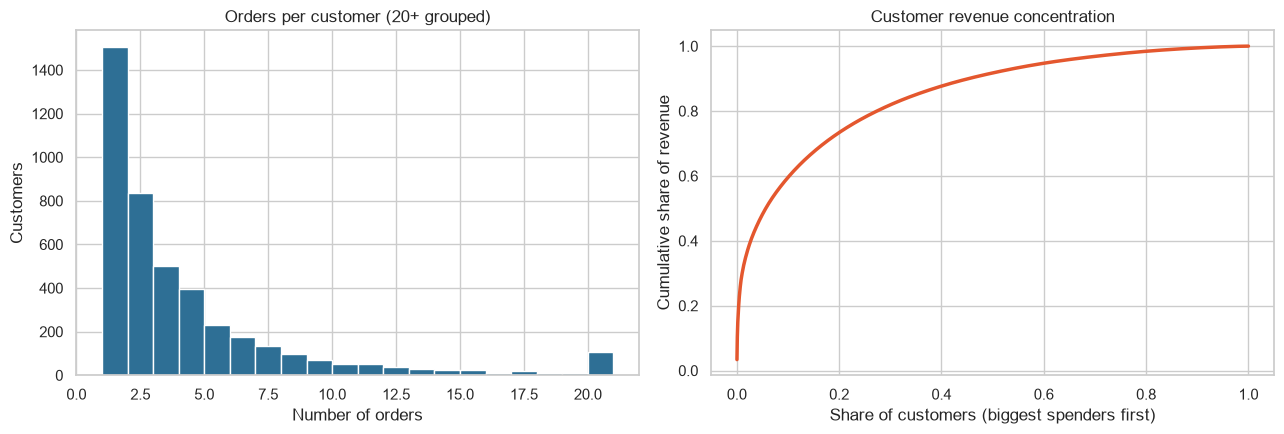

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(customers["Orders"].clip(upper=20), bins=range(1, 22), color="#2E6F95", edgecolor="white")
axes[0].set_title("Orders per customer (20+ grouped)")
axes[0].set_xlabel("Number of orders")
axes[0].set_ylabel("Customers")

axes[1].plot((np.arange(len(sorted_rev)) + 1) / len(sorted_rev), sorted_rev.cumsum() / sorted_rev.sum(),
             color="#E4572E", lw=2.5)
axes[1].set_title("Customer revenue concentration")
axes[1].set_xlabel("Share of customers (biggest spenders first)")
axes[1].set_ylabel("Cumulative share of revenue")

plt.tight_layout()
plt.savefig("../images/06_customer_behaviour.png", dpi=150)
plt.show()

### Findings: customers
- **65.1%** of identified customers ordered more than once, and they generate **93.4%** of identified revenue.
- The typical repeat customer spends about **£1,131** in total versus **£254** for a one-time customer (median), roughly 4.5x more.
- Average order value is similar for both groups (**£377 vs £362**), so repeat customers are worth more because they **order more often**, not because they spend more per order.
- The top 20% of customers produce **73.4%** of revenue, so the business depends on a relatively small group of loyal buyers.
- The orders-per-customer chart is heavily skewed: most customers place only a few orders, while a small group orders 20 or more times.
- Guest checkouts (about 25% of the original rows) can't be tracked, so they are excluded from this analysis. The 4,321 identified customers are the base for all customer conclusions.

## 9. Cohort retention
A **cohort** is a group of customers who made their first purchase in the same month. For each cohort I track what percentage ordered again 1, 2, 3... months later. This shows how quickly customers drop off.

Two rules keep the analysis honest:
- **Dec 2011 is excluded.** It is a partial month (data ends on 9 Dec) and would show artificially low retention.
- **The Dec 2010 cohort is special.** The data starts in Dec 2010, so this cohort also contains customers who were already buying before. It will look stronger than the real retention.

In [114]:
cc = known[known["Month"] <= "2011-11"].copy()          # complete months only

first_month = customers["FirstOrder"].dt.to_period("M")  # month of each customer's first order
cc["Cohort"] = cc["CustomerID"].map(first_month)
cc["CohortIndex"] = (cc["Month"] - cc["Cohort"]).apply(lambda x: x.n)   # months since first purchase

cc[["CustomerID", "InvoiceDate", "Cohort", "CohortIndex"]].head()

,CustomerID,InvoiceDate,Cohort,CohortIndex
0,17850,2010-12-01 08:26:00,2010-12,0
1,17850,2010-12-01 08:26:00,2010-12,0
2,17850,2010-12-01 08:26:00,2010-12,0
3,17850,2010-12-01 08:26:00,2010-12,0
4,17850,2010-12-01 08:26:00,2010-12,0


In [115]:
cohort = cc.groupby(["Cohort", "CohortIndex"])["CustomerID"].nunique().unstack()
retention = cohort.divide(cohort[0], axis=0)            # divide each row by its month-0 size
retention.index = retention.index.strftime("%b %y")

retention.round(2)

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11
Cohort,,,,,,,,,,,,
Dec 10,1.00,0.36,0.32,0.38,0.36,0.40,0.36,0.35,0.35,0.39,0.37,0.50
Jan 11,1.00,0.21,0.27,0.23,0.32,0.29,0.25,0.24,0.30,0.33,0.37,NaN
Feb 11,1.00,0.19,0.19,0.28,0.27,0.24,0.25,0.27,0.24,0.30,NaN,NaN
Mar 11,1.00,0.14,0.25,0.19,0.22,0.17,0.26,0.23,0.28,NaN,NaN,NaN
Apr 11,1.00,0.21,0.20,0.21,0.20,0.23,0.21,0.26,NaN,NaN,NaN,NaN
May 11,1.00,0.19,0.17,0.17,0.21,0.23,0.26,NaN,NaN,NaN,NaN,NaN
Jun 11,1.00,0.17,0.16,0.27,0.23,0.32,NaN,NaN,NaN,NaN,NaN,NaN
Jul 11,1.00,0.17,0.20,0.23,0.27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Aug 11,1.00,0.20,0.24,0.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


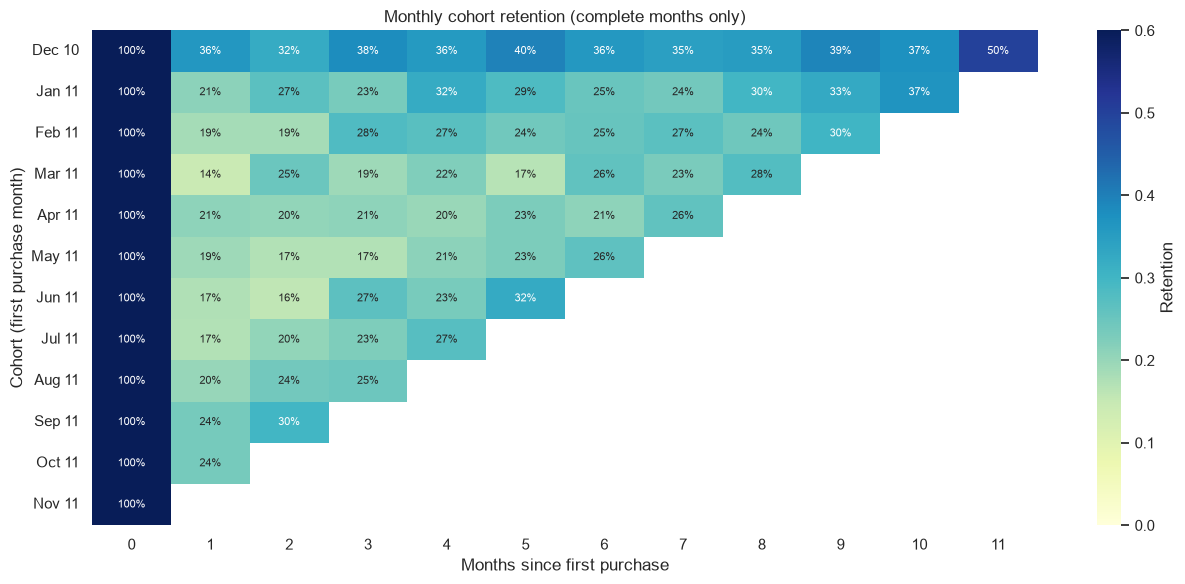

In [116]:
fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(retention, annot=True, fmt=".0%", cmap="YlGnBu", vmin=0, vmax=0.6,
            ax=ax, cbar_kws={"label": "Retention"}, annot_kws={"size": 8})
ax.grid(False)
ax.set_title("Monthly cohort retention (complete months only)")
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort (first purchase month)")

plt.tight_layout()
plt.savefig("../images/08_cohort_retention.png", dpi=150)
plt.show()

In [117]:
others = retention.iloc[1:]       # every cohort except Dec 10

print("Cohort sizes (new customers per month):")
print(cohort[0].to_string())

print(f"\nAvg month-1 retention, all cohorts   : {retention[1].mean():.1%}")
print(f"Avg month-1 retention, without Dec 10: {others[1].mean():.1%}")
print(f"Avg retention in months 2-6 (2011 cohorts): {others[[2, 3, 4, 5, 6]].mean().mean():.1%}")
print(f"Dec 10 cohort: month-1 {retention.loc['Dec 10', 1]:.0%}, month-6 {retention.loc['Dec 10', 6]:.0%}, month-11 {retention.loc['Dec 10', 11]:.0%}")

Cohort sizes (new customers per month):
Cohort
2010-12   882.00
2011-01   413.00
2011-02   381.00
2011-03   450.00
2011-04   299.00
2011-05   284.00
2011-06   241.00
2011-07   186.00
2011-08   170.00
2011-09   297.00
2011-10   355.00
2011-11   323.00
Freq: M

Avg month-1 retention, all cohorts   : 21.2%
Avg month-1 retention, without Dec 10: 19.7%
Avg retention in months 2-6 (2011 cohorts): 23.8%
Dec 10 cohort: month-1 36%, month-6 36%, month-11 50%


### Findings: cohort retention
- On average only **about 20%** of a cohort orders again in the month after its first purchase (19.7% for the 2011 cohorts), so roughly 4 in 5 new customers do not return quickly.
- After the first month, retention does **not keep falling**. It stays around **24%** in months 2-6 and sometimes rises (for example 30% for the Jan and Feb 2011 cohorts at month 9). Customers tend to come back around seasonal moments rather than leave for good.
- The Dec 2010 cohort looks much stronger (**36%** at month 1, **50%** at month 11) because it includes customers who were already active before the data starts, so it overstates true retention.
- **New-customer acquisition** (cohort sizes) fell from **413 in Jan 2011 to 170 in Aug 2011** (down 59%), then recovered in autumn (297, 355 and 323 in Sep to Nov). Growth outside the Q4 peak depends mostly on existing customers.
- Each percentage is the share of the cohort that bought **in that specific month**, not the share that ever came back. That is why month-1 retention is about 20% while 65% of all customers eventually order more than once: many return later, just not the following month.

## 10. RFM segmentation
RFM scores every customer from 1 (worst) to 5 (best) on three measures:
- **Recency**: days since the last order
- **Frequency**: number of orders
- **Monetary**: total spend

The scores are combined into segments the business can act on:

| Segment | Rule | Meaning |
|---|---|---|
| Champions | R >= 4 and F >= 4 | Recent and frequent buyers |
| Loyal | R >= 3 and F >= 3 | Solid regulars |
| Promising / New | R >= 3 and F <= 2 | Recent, but few orders so far |
| Can't lose them | R <= 2 and F >= 4 | Used to buy a lot, gone quiet |
| At risk | R <= 2 and F = 3 | Slipping away |
| Hibernating | R <= 2 and F <= 2 | Inactive, low engagement |

In [118]:
snapshot = df_clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)   # "today" for the analysis

rfm = known.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
)

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12347,2,7,"4,310.00"
12348,75,4,"1,437.24"
12349,18,1,"1,457.55"
12350,310,1,294.40
12352,36,5,"1,125.28"


In [119]:
rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm.head()

,Recency,Frequency,Monetary,R,F,M
CustomerID,,,,,,
12347,2,7,"4,310.00",5,5,5
12348,75,4,"1,437.24",2,4,4
12349,18,1,"1,457.55",4,1,4
12350,310,1,294.40,1,1,2
12352,36,5,"1,125.28",3,4,4


In [120]:
def segment(row):
    if row["R"] >= 4 and row["F"] >= 4: return "Champions"
    if row["R"] >= 3 and row["F"] >= 3: return "Loyal"
    if row["R"] >= 3 and row["F"] <= 2: return "Promising / New"
    if row["R"] <= 2 and row["F"] >= 4: return "Can't lose them"
    if row["R"] <= 2 and row["F"] == 3: return "At risk"
    return "Hibernating"

rfm["Segment"] = rfm.apply(segment, axis=1)

seg = rfm.groupby("Segment").agg(
    Customers=("Monetary", "size"),
    Revenue=("Monetary", "sum"),
    AvgRecency=("Recency", "mean"),
    AvgOrders=("Frequency", "mean"),
    AvgSpend=("Monetary", "mean"),
)
seg["% Customers"] = seg["Customers"] / seg["Customers"].sum()
seg["% Revenue"] = seg["Revenue"] / seg["Revenue"].sum()
seg = seg.sort_values("Revenue", ascending=False)

seg[["Customers", "% Customers", "% Revenue", "AvgRecency", "AvgOrders", "AvgSpend"]]

,Customers,% Customers,% Revenue,AvgRecency,AvgOrders,AvgSpend
Segment,,,,,,
Champions,1119,0.26,0.69,12.60,9.88,"5,047.74"
Loyal,824,0.19,0.14,36.92,3.60,"1,375.13"
Hibernating,1076,0.25,0.05,217.34,1.10,415.28
Can't lose them,283,0.07,0.05,137.25,4.79,"1,527.06"
Promising / New,653,0.15,0.03,36.09,1.18,438.93
At risk,366,0.08,0.03,161.87,2.26,752.37


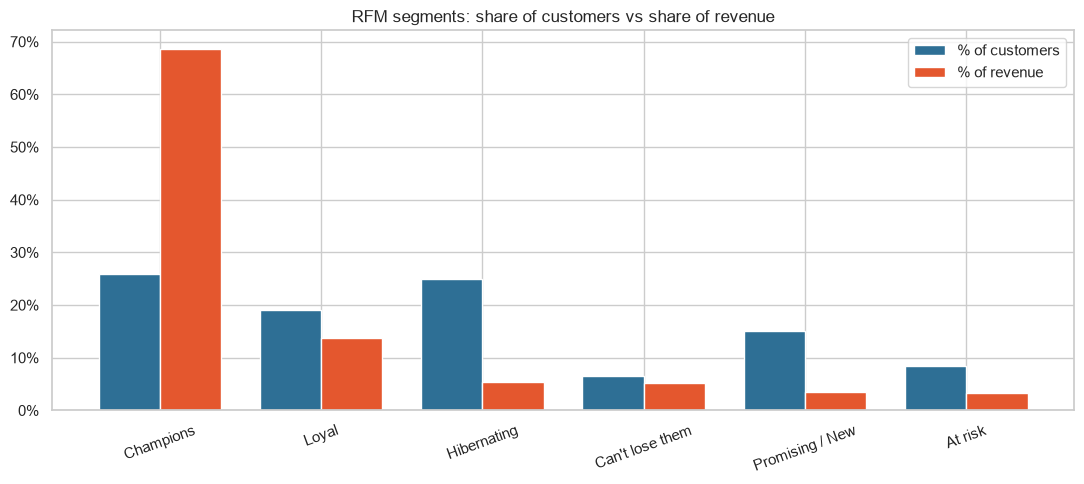

In [121]:
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(seg))
w = 0.38
ax.bar(x - w/2, seg["% Customers"], w, label="% of customers", color="#2E6F95")
ax.bar(x + w/2, seg["% Revenue"], w, label="% of revenue", color="#E4572E")

ax.set_xticks(x)
ax.set_xticklabels(seg.index, rotation=20)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("RFM segments: share of customers vs share of revenue")
ax.legend()

plt.tight_layout()
plt.savefig("../images/09_rfm_segments.png", dpi=150)
plt.show()

In [122]:
champ = seg.loc["Champions"]
risk = seg.loc[["At risk", "Can't lose them"]]

print(f"Champions: {champ['% Customers']:.1%} of customers -> {champ['% Revenue']:.1%} of revenue")
print(f"At risk + Can't lose them: {risk['Customers'].sum():,} customers, £{risk['Revenue'].sum():,.0f} ({risk['Revenue'].sum() / seg['Revenue'].sum():.1%} of revenue)")
print(f"Hibernating: {seg.loc['Hibernating', 'Customers']:,} customers ({seg.loc['Hibernating', '% Customers']:.1%}), {seg.loc['Hibernating', '% Revenue']:.1%} of revenue")
print(f"Promising / New: {seg.loc['Promising / New', 'Customers']:,} customers ({seg.loc['Promising / New', '% Customers']:.1%}), {seg.loc['Promising / New', '% Revenue']:.1%} of revenue")

Champions: 25.9% of customers -> 68.7% of revenue
At risk + Can't lose them: 649 customers, £707,524 (8.6% of revenue)
Hibernating: 1,076 customers (24.9%), 5.4% of revenue
Promising / New: 653 customers (15.1%), 3.5% of revenue


    ### Findings: RFM segmentation
- **Champions** are 25.9% of customers but generate **68.7% of revenue** (average spend £5,036, last order about 13 days before the data ends). They are the core of the business.
- **At risk + Can't lose them** are **649 customers holding £705K (8.6% of revenue)**. "Can't lose them" customers (283) used to order almost 5 times each (average spend £1,521) and have been silent for about 137 days. This is the best win-back list.
- **Hibernating** customers are 24.9% of customers but only 5.4% of revenue (average of 1.1 orders, silent for over 200 days). They are low value and not worth heavy spending.
- **Promising / New** (653 customers, 15.1%) ordered recently but only about once (1.2 orders on average) and bring just 3.5% of revenue. This is where a second-order nudge matters most, which connects to the weak month-1 retention in the cohort analysis.
- Together, Champions and Loyal are 45% of customers and 83% of revenue.

## 11. Returns and cancellations
Cancelled invoices were set aside during cleaning. Here I measure how much value they represent and which products are cancelled most, since cancellations point to product, stock or delivery problems.

Two bulk orders (about 75K and 81K units) were cancelled within minutes. These are entry reversals, not customer behaviour, so I exclude them here.

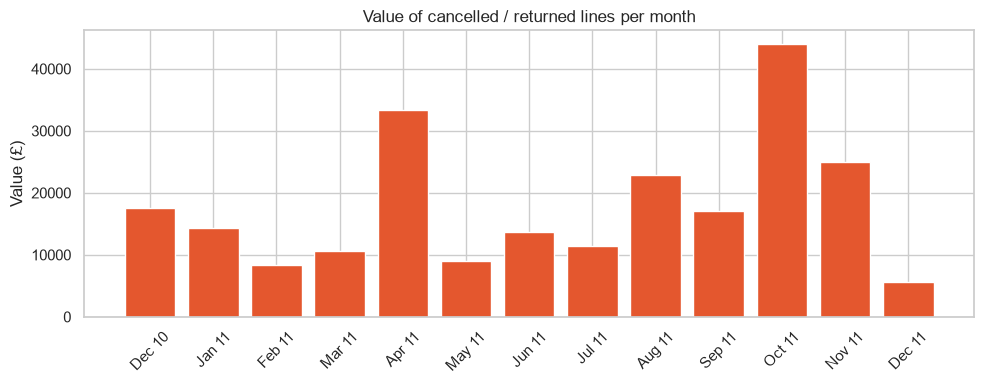

In [123]:
ret = returns[~returns["StockCode"].str.upper().isin(NON_PRODUCT) & (returns["Quantity"].abs() < 10000)].copy()

ret["Value"] = -(ret["Quantity"] * ret["UnitPrice"])      # make it positive: money lost
ret["Month"] = ret["InvoiceDate"].dt.to_period("M")

monthly_ret = ret.groupby("Month")["Value"].sum()
monthly_ret.index = monthly_ret.index.strftime("%b %y")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly_ret.index, monthly_ret.values, color="#E4572E")
ax.set_title("Value of cancelled / returned lines per month")
ax.set_ylabel("Value (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../images/10_returns.png", dpi=150)
plt.show()

In [124]:
print(f"Cancelled value: £{ret['Value'].sum():,.0f} = {ret['Value'].sum() / df_clean['Revenue'].sum():.1%} of net sales")
print(f"Customers with at least one cancellation: {ret['CustomerID'].nunique():,} ({ret['CustomerID'].nunique() / len(customers):.1%} of identified customers)")

print("\nMost-cancelled products by value:")
ret.groupby("Description")["Value"].sum().sort_values(ascending=False).head(6).round(0)

Cancelled value: £233,071 = 2.4% of net sales
Customers with at least one cancellation: 1,532 (35.5% of identified customers)

Most-cancelled products by value:


Description
REGENCY CAKESTAND 3 TIER             9,723.00
WHITE HANGING HEART T-LIGHT HOLDER   6,624.00
FAIRY CAKE FLANNEL ASSORTED COLOUR   6,591.00
PANTRY CHOPPING BOARD                4,803.00
DOORMAT FAIRY CAKE                   4,555.00
GIN + TONIC DIET METAL SIGN          3,775.00
Name: Value, dtype: float64

### Findings: returns and cancellations
- Cancelled product lines are worth about **£233K, roughly 2.4% of net sales**, a small share. The figure is approximate, because cancelled orders that were matched during cleaning are already out of net sales.
- **1,532 customers (about 35% of identified customers)** cancelled at least one line.
- The most-cancelled products by value are the **Regency Cakestand 3 Tier (£9.7K)** and the **White Hanging Heart T-Light Holder (£6.6K)**. These are also two of the three top revenue earners, so heavy sellers are cancelled most in absolute terms. The data can't say why (breakage, expectations, delivery), so this needs follow-up with the business.

## 12. Business recommendations

| # | Insight from the data | Recommendation |
|---|---|---|
| 1 | Only ~20% of new customers order again in month 1; "Promising / New" is 653 customers with ~1.2 orders each | Send a second-order nudge (reminder or small incentive) in the first weeks after a first purchase. **KPI to track: month-1 retention (baseline ~20%).** |
| 2 | "Can't lose them" + "At risk" = 649 customers holding £705K (8.6% of revenue), silent for 4-5 months | Run a win-back campaign aimed at these two segments first. |
| 3 | Champions are 26% of customers but 69% of revenue | Protect them: early access, loyalty perks, and never run out of hero products. Avoid discounts they don't need. |
| 4 | Sep-Nov revenue doubles vs earlier months; orders are mostly 10:00-15:59 on weekdays | Plan stock and marketing for Q4 by August, and send campaigns in the morning on weekdays. |
| 5 | New customers fell 59% from Jan to Aug 2011 | Test acquisition spend outside Q4 so growth does not depend only on the autumn peak. |
| 6 | 982 products earned under £100; top 20% of products give 79% of revenue | Review the long tail (reduce stock, bundle or drop) and keep hero products always in stock. |
| 7 | Cakestand and T-light holder are also the most-cancelled products | Investigate quality, packaging and product-page expectations for them. |
| 8 | Netherlands and EIRE: 12 customers behind ~5.5% of revenue; Germany and France have 80+ customers each | Assign account management to the large export buyers and target marketing at Germany and France. |
| 9 | 25% of rows have no CustomerID | Encourage account creation at checkout so more behaviour can be tracked. |

### Limitations
- Customer analysis covers only identified customers (the other ~25% of rows are guest checkouts).
- The cancellation matching is approximate (same customer, product and quantity).
- Dec 2011 is a partial month, and the Dec 2010 cohort includes customers who were active before the data starts.
- The data covers 12 months, so seasonality is observed for one year only.
